In [135]:
import pandas as pd
import re
import os
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import FuncFormatter

In [136]:
df = pd.read_parquet("../data/cleaned_merged_df.parquet",columns=['pt_id',
 'admission_id',
 'admission_duration',
 
 'dama',
 'reason_for_dama',

 'ckd',
 'cause_ckd',
 'dialysis',

 'stroke',
 'dm',
 'cancer',
 'type_of_cancer',
 'pud',
 'doctor',

 'doctors_specialization',
 'pt_name',
 'pt_age',
 'pt_sex',
 'pt_occupation',
 'pt_level_of_education',
 'pt_marital_status',
 'alcohol_hx',
 'tobacco_hx',
 'nsaid_use',
 'age_group',
 "age_range",
 "admission_group"])
df.head()

,pt_id,admission_id,admission_duration,dama,reason_for_dama,ckd,cause_ckd,dialysis,stroke,dm,...,pt_sex,pt_occupation,pt_level_of_education,pt_marital_status,alcohol_hx,tobacco_hx,nsaid_use,age_group,age_range,admission_group
0,1,101,16,no,NaN,no,NaN,no,yes,no,...,m,trading,NaN,married,no,no,yes,Older adults,60-74,Long stay
1,2,102,8,no,NaN,no,NaN,no,no,no,...,m,retiree,NaN,married,no,no,yes,Older adults,60-74,Extended stay
2,3,103,6,no,NaN,no,NaN,no,no,no,...,m,computer scientist,ba,married,yes,no,yes,Middle-aged adults,45-59,Moderate stay
3,4,104,13,no,NaN,no,NaN,no,no,no,...,m,retiree,NaN,married,no,no,yes,Elderly adults,75+,Extended stay
4,5,105,30,no,NaN,no,NaN,no,no,no,...,f,retiree,NaN,married,no,no,yes,Elderly adults,75+,Long stay


In [137]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1478 entries, 0 to 1477
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   pt_id                   1478 non-null   int64  
 1   admission_id            1478 non-null   int64  
 2   admission_duration      1478 non-null   int64  
 3   dama                    1478 non-null   str    
 4   reason_for_dama         276 non-null    str    
 5   ckd                     1478 non-null   str    
 6   cause_ckd               326 non-null    str    
 7   dialysis                1478 non-null   str    
 8   stroke                  1478 non-null   str    
 9   dm                      1478 non-null   str    
 10  cancer                  1478 non-null   str    
 11  type_of_cancer          32 non-null     str    
 12  pud                     1478 non-null   str    
 13  doctor                  1478 non-null   str    
 14  doctors_specialization  1478 non-null   str    
 15

In [138]:
df["reason_for_dama"].value_counts()

reason_for_dama
financial constraint      224
financial incapability     19
no improvement             19
doctors'  strike           14
Name: count, dtype: int64

In [139]:
reason = df.groupby(["reason_for_dama"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values(by="count",ascending=False)
reason["total_count"] = reason["count"].sum()
reason["pct"] = (reason["count"]/reason["total_count"] * 100).round(2)
reason

,reason_for_dama,count,total_count,pct
1,financial constraint,224,276,81.16
2,financial incapability,19,276,6.88
3,no improvement,19,276,6.88
0,doctors' strike,14,276,5.07


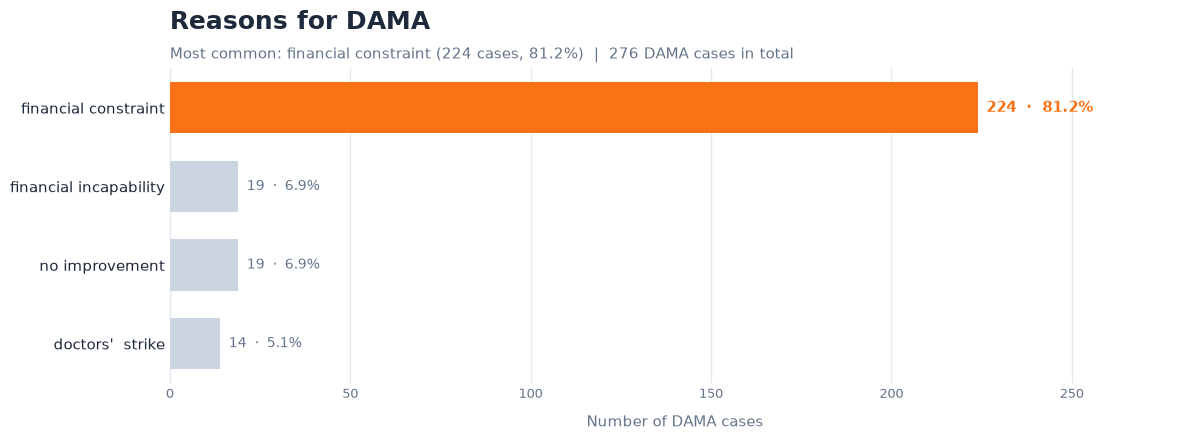

In [140]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 12   # max reasons to show

# ---------------- Prep ----------------
data = (reason.sort_values("count", ascending=False)
        .head(TOP_N).reset_index(drop=True))
labels = data["reason_for_dama"].astype(str).apply(lambda s: textwrap.fill(s, 32))
counts = data["count"]

total_all = reason["count"].sum()
shares    = counts / total_all * 100
top_label = data["reason_for_dama"].iloc[0]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12, max(4.5, len(data) * 0.62 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
bars = ax.barh(labels, counts, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()   # most common at the top

# Labels: count and share of all DAMA cases
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}  ·  {s:.1f}%" for c, s in zip(counts, shares)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Titles
ax.set_title("Reasons for DAMA", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most common: {top_label} ({counts.iloc[0]:,.0f} cases, {shares.iloc[0]:.1f}%)  |  "
        f"{total_all:,.0f} DAMA cases in total",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of DAMA cases", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/reasons_for_dama.png", dpi=180)
plt.show()

In [141]:
df["dama"].value_counts()

dama
no     1202
yes     276
Name: count, dtype: int64

In [142]:
df["ckd"].value_counts()

ckd
no     1154
yes     324
Name: count, dtype: int64

In [143]:
(df["ckd"] == "yes").sum()

np.int64(324)

In [144]:
dama_percent = df.groupby("dama").agg(
    count = ("pt_id","count")
).reset_index()
dama_percent["pct"] = (( dama_percent["count"]/df["dama"].count()) * 100).round(2)
dama_percent

,dama,count,pct
0,no,1202,81.33
1,yes,276,18.67


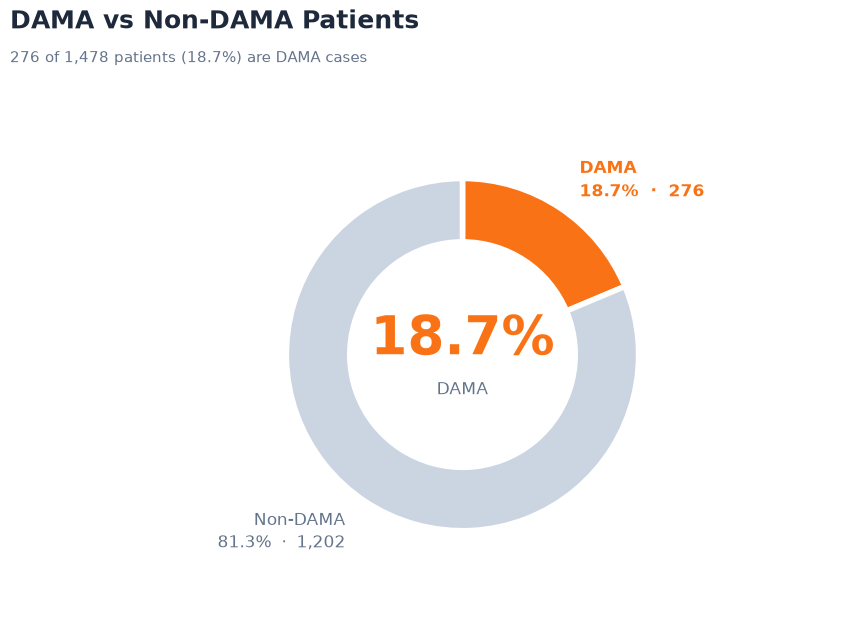

In [145]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GREYS = ["#CBD5E1", "#94A3B8", "#64748B"]   # used if dama has more than 2 values

# ---------------- Prep ----------------
d = dama_percent.copy()
d["dama"] = d["dama"].astype(str)

# Which value is the DAMA one (set hi_val by hand if your column uses something else)
yes_words = {"yes", "y", "1", "1.0", "true"}
hit = [v for v in d["dama"] if v.strip().lower() in yes_words]
hi_val = hit[0] if hit else d.loc[d["count"].idxmax(), "dama"]

# DAMA slice first, so it starts at the top
d = pd.concat([d[d["dama"] == hi_val], d[d["dama"] != hi_val]]).reset_index(drop=True)
counts, pcts, names = d["count"], d["pct"], d["dama"]
total = counts.sum()

colors, g = [], 0
for v in names:
    if v == hi_val:
        colors.append(PEAK)
    else:
        colors.append(GREYS[g % len(GREYS)]); g += 1

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(10, 7.5))
fig.patch.set_facecolor("white")

ax.pie(counts, colors=colors, startangle=90, counterclock=False,
       wedgeprops=dict(width=0.36, edgecolor="white", linewidth=4))
ax.set_aspect("equal")
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-1.45, 1.45)

# Center text: the DAMA share
ax.text(0, 0.08, f"{pcts.iloc[0]:.1f}%", ha="center", va="center",
        fontsize=38, fontweight="bold", color=PEAK)
ax.text(0, -0.2, "DAMA", ha="center", va="center", fontsize=12, color=MUTED)

# Outside labels: name, share, count
edges = np.cumsum([0] + list(counts)) / total * 360
for i in range(len(d)):
    mid = np.deg2rad(90 - (edges[i] + edges[i + 1]) / 2)
    x, y = 1.2 * np.cos(mid), 1.2 * np.sin(mid)
    hot = names.iloc[i] == hi_val
    label = "DAMA" if hot else ("Non-DAMA" if len(d) == 2 else names.iloc[i])
    ax.text(x, y, f"{label}\n{pcts.iloc[i]:.1f}%  ·  {counts.iloc[i]:,}",
            ha="left" if x >= 0 else "right", va="center", fontsize=12,
            fontweight="bold" if hot else "normal",
            color=PEAK if hot else MUTED, linespacing=1.4)

ax.axis("off")

# Titles
fig.text(0.06, 0.93, "DAMA vs Non-DAMA Patients", fontsize=18, fontweight="bold", color=TEXT)
fig.text(0.06, 0.885, f"{counts.iloc[0]:,} of {total:,} patients ({pcts.iloc[0]:.1f}%) are DAMA cases",
         fontsize=11, color=MUTED)


plt.savefig("../images/dama_vs_non_dama.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()

In [146]:
dama_disease = df.groupby(["dama","ckd","pud","stroke","dm","cancer"]).agg(
    count = ("pt_id","count")
).reset_index()
dama_disease

,dama,ckd,pud,stroke,dm,cancer,count
0,no,no,no,no,no,no,598
1,no,no,no,no,no,yes,3
2,no,no,no,no,yes,no,9
3,no,no,no,no,yes,yes,19
4,no,no,no,yes,no,no,183
5,no,no,no,yes,yes,no,5
6,no,no,no,yes,yes,yes,2
7,no,no,yes,no,no,no,82
8,no,no,yes,yes,no,no,30
9,no,no,yes,yes,yes,yes,1


In [147]:
diseases = ["dama", "ckd", "pud", "stroke","dm" ,"cancer"]
tot_dama_cases = 276
for disease in diseases:
    print(disease)

    dama_cases = (
        dama_disease[dama_disease["dama"] == "yes"]
        .groupby(disease)["count"]
        .sum()
        .get("yes", 0)
    ) # number of disease cases where there was discharge againt medical advice


    
    
    total_cases = (df[disease] == "yes").sum()

    percentage = round((dama_cases / total_cases) * 100, 2) if total_cases > 0 else 0
    dama_percentage = round((dama_cases / tot_dama_cases) * 100, 2) 
    print(f"Total number of people with {disease} discharged against medical advice: {dama_cases}")
    print(f"Total number of cases with {disease}: {total_cases}")
    print(f"Percentage of {disease} patients that were discharges againt medical advice: {percentage}%")
    print(f"Percentage of all DAMA patients represented: {dama_percentage}%")
    print("*************************************")

dama
Total number of people with dama discharged against medical advice: 276
Total number of cases with dama: 276
Percentage of dama patients that were discharges againt medical advice: 100.0%
Percentage of all DAMA patients represented: 100.0%
*************************************
ckd
Total number of people with ckd discharged against medical advice: 54
Total number of cases with ckd: 324
Percentage of ckd patients that were discharges againt medical advice: 16.67%
Percentage of all DAMA patients represented: 19.57%
*************************************
pud
Total number of people with pud discharged against medical advice: 24
Total number of cases with pud: 168
Percentage of pud patients that were discharges againt medical advice: 14.29%
Percentage of all DAMA patients represented: 8.7%
*************************************
stroke
Total number of people with stroke discharged against medical advice: 61
Total number of cases with stroke: 347
Percentage of stroke patients that were disc

In [148]:
#are there certain doctors causing more dama

doctor_dama = df.groupby(["doctor","doctors_specialization" ,"dama"]).agg(
    count=("pt_id", "count")
).reset_index()



doctor_summary = doctor_dama.pivot(
    index=["doctor","doctors_specialization"],
    columns="dama",
    values="count"
).fillna(0).reset_index()

doctor_summary["total_patients"] = (
    doctor_summary["yes"] + doctor_summary["no"]
)

doctor_summary["dama_rate"] = (
    doctor_summary["yes"]
    / doctor_summary["total_patients"] * 100
).round(2)

doctor_summary = doctor_summary.rename(
    columns={"yes": "dama_cases", "no": "non_dama_cases"}
)

doctor_summary = doctor_summary.sort_values(
    "dama_rate", ascending=False
)

# doctor_dama
doctors_with_high_dama_rates = doctor_summary.head(10)

print(f"Doctors with high dama rates")
doctors_with_high_dama_rates


Doctors with high dama rates


dama,doctor,doctors_specialization,non_dama_cases,dama_cases,total_patients,dama_rate
33,dr salu,nephrology,9.0,6.0,15.0,40.00
28,dr oikeh,anesthesiology,17.0,10.0,27.0,37.04
30,dr oluwole,anesthesiology,14.0,7.0,21.0,33.33
25,dr ndubuisi,general surgery,12.0,6.0,18.0,33.33
19,dr ekwe,general surgery,30.0,13.0,43.0,30.23
16,dr daniel,general surgery,33.0,14.0,47.0,29.79
15,dr badmus,general surgery,37.0,15.0,52.0,28.85
27,dr ogedegbe,emergency medicine,125.0,49.0,174.0,28.16
3,dr ajakaiye,orthopedics,13.0,5.0,18.0,27.78
4,dr ajani,orthopedics,14.0,5.0,19.0,26.32


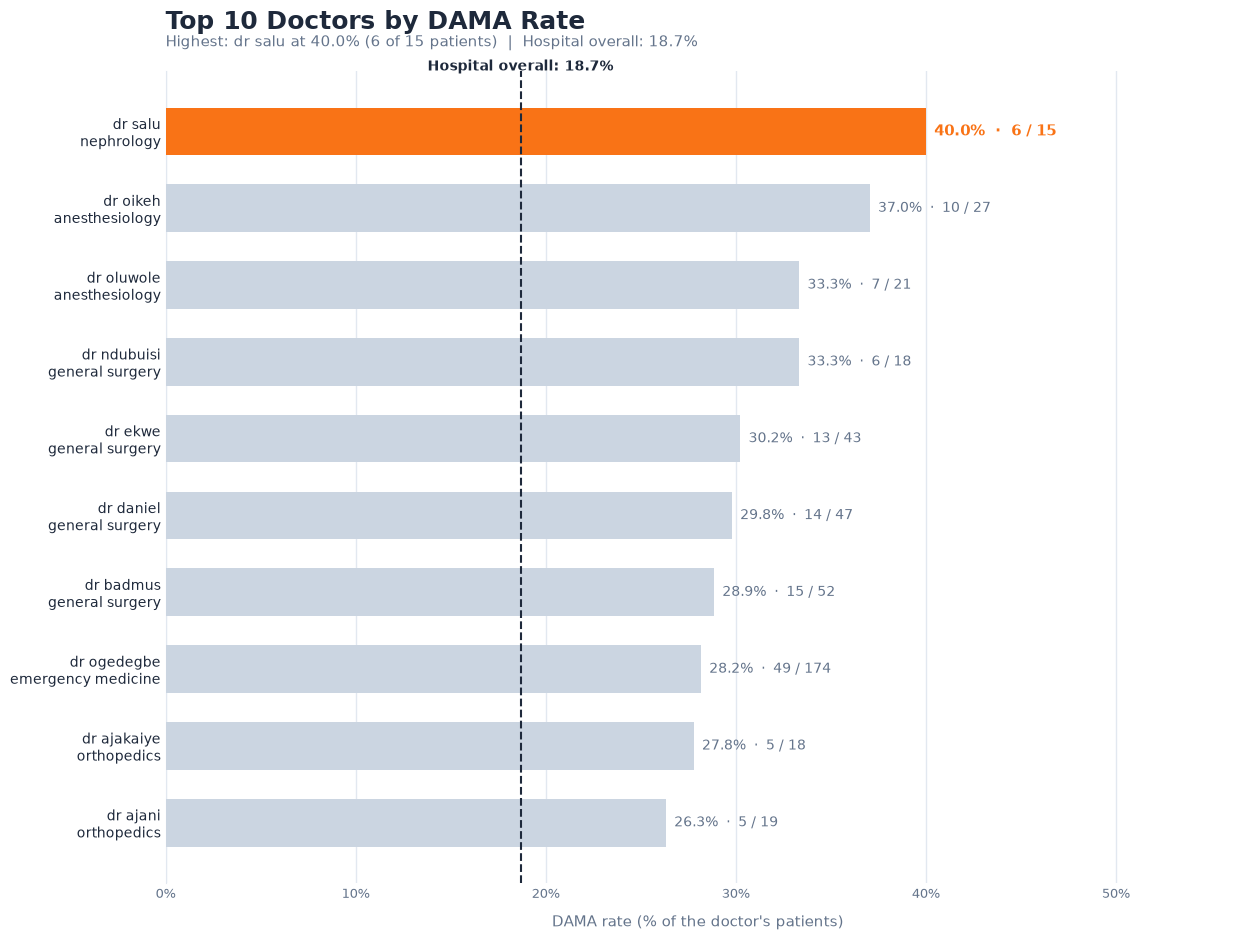

In [165]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
data = (doctors_with_high_dama_rates
        .sort_values("dama_rate", ascending=False).reset_index(drop=True))

labels = [f"{textwrap.fill(str(d), 26)}\n{textwrap.fill(str(s), 30)}"
          for d, s in zip(data["doctor"], data["doctors_specialization"])]
rates  = data["dama_rate"]
cases  = data["dama_cases"].astype(int)
total  = data["total_patients"].astype(int)

# Hospital-wide DAMA rate (all doctors, not just the top 10)
overall = doctor_summary["dama_cases"].sum() / doctor_summary["total_patients"].sum() * 100

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12.5, max(5, len(data) * 0.75 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
ypos = np.arange(len(data))
bars = ax.barh(ypos, rates, color=colors, height=0.62, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.invert_yaxis()   # highest rate at the top

# Labels: rate and cases / total patients
t = ax.bar_label(bars,
                 labels=[f"{r:.1f}%  ·  {c:,} / {n:,}" for r, c, n in zip(rates, cases, total)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Overall rate reference line
ax.axvline(overall, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(overall, -0.75, f"Hospital overall: {overall:.1f}%", ha="center", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("Top 10 Doctors by DAMA Rate", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=30)
ax.text(0, 1.03,
        f"Highest: {data['doctor'].iloc[0]} at {rates.iloc[0]:.1f}% "
        f"({cases.iloc[0]:,} of {total.iloc[0]:,} patients)  |  "
        f"Hospital overall: {overall:.1f}%",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("DAMA rate (% of the doctor's patients)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, rates.max() * 1.4)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="y", labelsize=10, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/top_doctors_dama_rate.png", dpi=180)
plt.show()

In [149]:
doctors_with_low_dama_rates = doctor_summary.tail(10)
doctors_with_low_dama_rates

dama,doctor,doctors_specialization,non_dama_cases,dama_cases,total_patients,dama_rate
22,dr kenneth,dermatology,29.0,3.0,32.0,9.38
18,dr davies,nephrology,39.0,3.0,42.0,7.14
24,dr mahmoud,general surgery,14.0,1.0,15.0,6.67
9,dr amadasun,nephrology,14.0,1.0,15.0,6.67
5,dr akeju,orthopedics,15.0,1.0,16.0,6.25
23,dr lash,dermatology,65.0,3.0,68.0,4.41
7,dr alade,nephrology,23.0,1.0,24.0,4.17
2,dr adenuga,orthopedics,8.0,0.0,8.0,0.00
6,dr akinola,orthopedics,13.0,0.0,13.0,0.00
10,dr anosike,nephrology,1.0,0.0,1.0,0.00


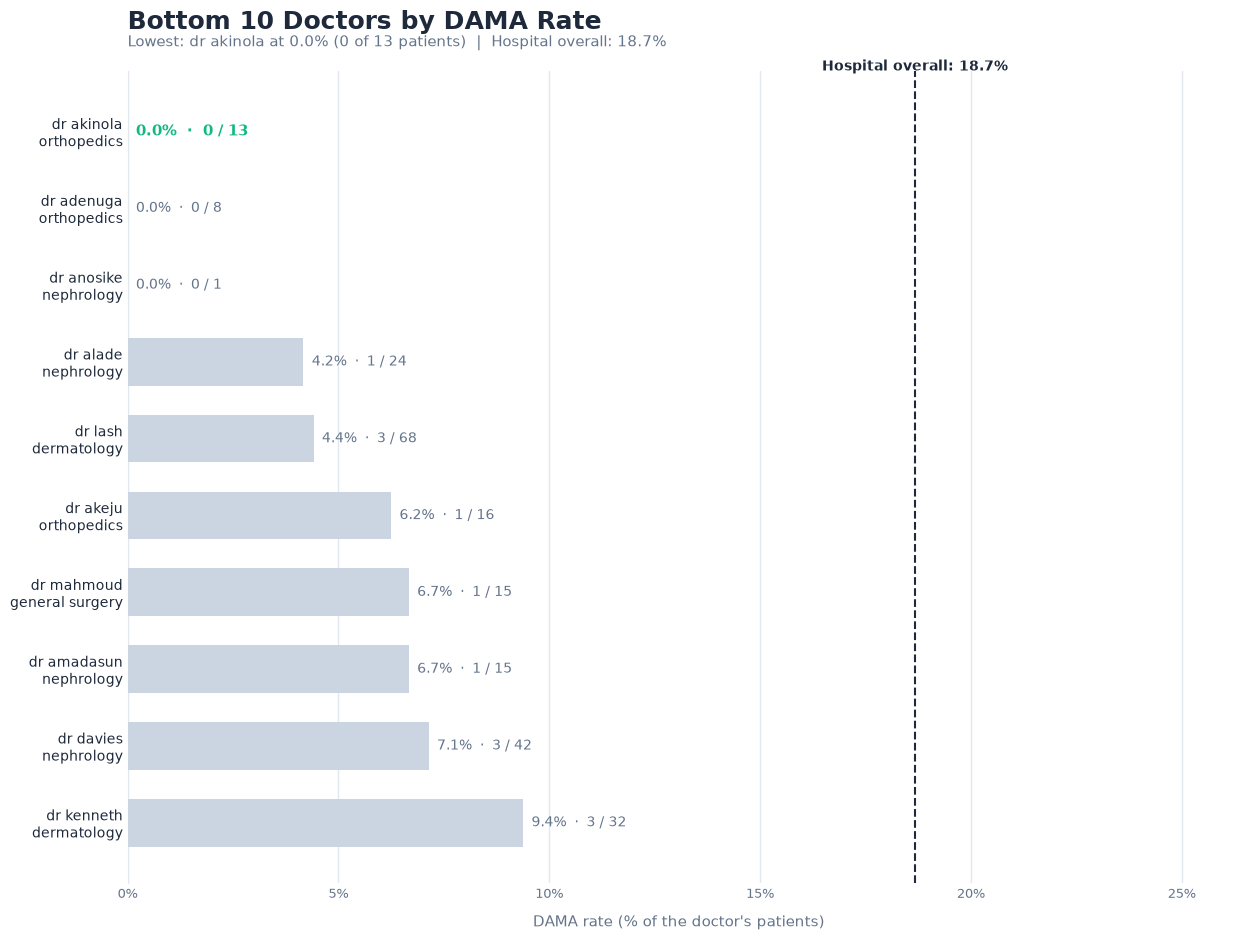

In [166]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
GOOD  = "#10B981"   # lowest rate = best, so green instead of orange
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
# Lowest rate first; ties broken by more patients first (more reliable)
data = (doctors_with_low_dama_rates
        .sort_values(["dama_rate", "total_patients"], ascending=[True, False])
        .reset_index(drop=True))

labels = [f"{textwrap.fill(str(d), 26)}\n{textwrap.fill(str(s), 30)}"
          for d, s in zip(data["doctor"], data["doctors_specialization"])]
rates  = data["dama_rate"]
cases  = data["dama_cases"].astype(int)
total  = data["total_patients"].astype(int)

# Hospital-wide DAMA rate (all doctors, not just these 10)
overall = doctor_summary["dama_cases"].sum() / doctor_summary["total_patients"].sum() * 100

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12.5, max(5, len(data) * 0.75 + 2)))
fig.patch.set_facecolor("white")

colors = [GOOD if i == 0 else BASE for i in range(len(data))]
ypos = np.arange(len(data))
bars = ax.barh(ypos, rates, color=colors, height=0.62, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.invert_yaxis()   # lowest rate at the top

# Labels: rate and cases / total patients (also shows for 0% bars)
t = ax.bar_label(bars,
                 labels=[f"{r:.1f}%  ·  {c:,} / {n:,}" for r, c, n in zip(rates, cases, total)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(GOOD)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Overall rate reference line
ax.axvline(overall, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(overall, -0.75, f"Hospital overall: {overall:.1f}%", ha="center", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("Bottom 10 Doctors by DAMA Rate", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=30)
ax.text(0, 1.03,
        f"Lowest: {data['doctor'].iloc[0]} at {rates.iloc[0]:.1f}% "
        f"({cases.iloc[0]:,} of {total.iloc[0]:,} patients)  |  "
        f"Hospital overall: {overall:.1f}%",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("DAMA rate (% of the doctor's patients)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, max(rates.max(), overall) * 1.4)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="y", labelsize=10, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/bottom_doctors_dama_rate.png", dpi=180)
plt.show()

In [150]:
dama_age_group = df.groupby(["age_group","dama"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
dama_age_group

,age_group,dama,count
6,Older adults,no,384
4,Middle-aged adults,no,326
0,Adults,no,265
2,Elderly adults,no,128
9,Young adults,no,94
5,Middle-aged adults,yes,82
7,Older adults,yes,80
1,Adults,yes,62
10,Young adults,yes,34
3,Elderly adults,yes,16


In [151]:
#which age group dama
dama_age_group = df.groupby(["age_group","age_range","dama"]).agg(
    count = ("pt_id","count")
).reset_index()

dama_age_group_summary = dama_age_group.pivot(index=["age_group","age_range"],columns="dama",values="count").fillna(0).reset_index()

dama_age_group_summary["total_patients"] = (
    dama_age_group_summary["yes"] + dama_age_group_summary["no"]
)

dama_age_group_summary["dama_rate"] = (
    dama_age_group_summary["yes"]
    / dama_age_group_summary["total_patients"] * 100
).round(2)

dama_age_group_summary = dama_age_group_summary.rename(
    columns={"yes": "dama_cases", "no": "non_dama_cases"}
)

dama_age_group_summary = dama_age_group_summary.sort_values(
    "dama_rate", ascending=False
)

dama_age_group_summary

dama,age_group,age_range,non_dama_cases,dama_cases,total_patients,dama_rate
5,Young adults,18-29,94.0,34.0,128.0,26.56
2,Middle-aged adults,45-59,326.0,82.0,408.0,20.10
0,Adults,30-44,265.0,62.0,327.0,18.96
3,Older adults,60-74,384.0,80.0,464.0,17.24
1,Elderly adults,75+,128.0,16.0,144.0,11.11
4,Under 18,0-17,2.0,0.0,2.0,0.00


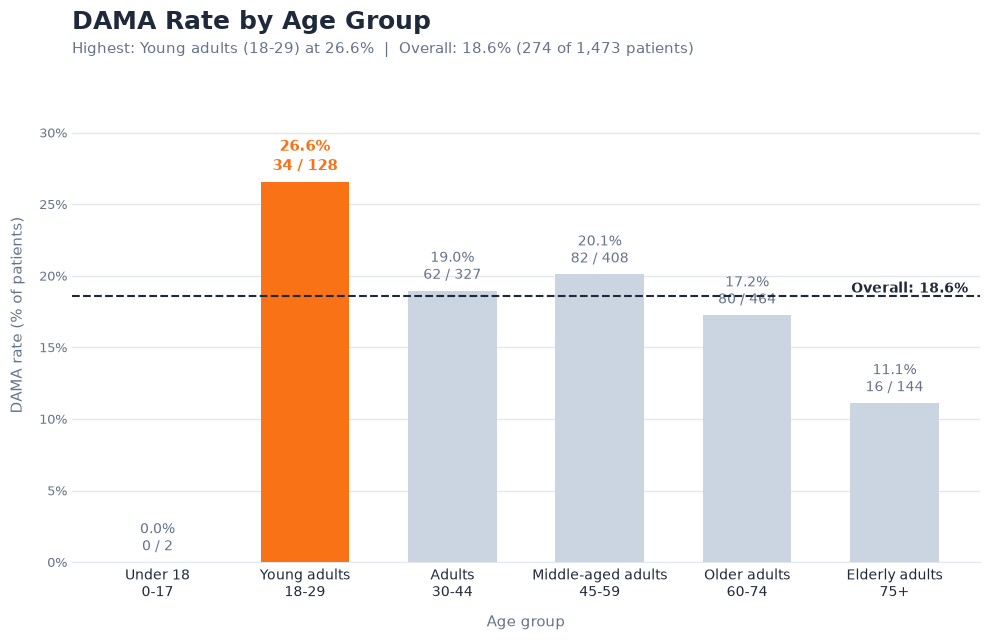

In [152]:
# --- Palette  ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
data = dama_age_group_summary.copy()
data["age_group"] = data["age_group"].astype(str)
data["age_range"] = data["age_range"].astype(str)

# Natural age order (youngest to oldest) using the first number in age_range
nums = data["age_range"].str.extract(r"(\d+)")[0]
if nums.notna().all():
    data = data.assign(_k=nums.astype(int)).sort_values("_k").drop(columns="_k")
data = data.reset_index(drop=True)

labels = data["age_group"] + "\n" + data["age_range"]
rates  = data["dama_rate"]
cases  = data["dama_cases"].astype(int)
total  = data["total_patients"].astype(int)

overall = data["dama_cases"].sum() / data["total_patients"].sum() * 100
hi = int(rates.values.argmax())

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, len(data) * 1.5), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(labels, rates, color=colors, width=0.6, zorder=3)

# Labels: rate on top, cases / total underneath
t = ax.bar_label(bars,
                 labels=[f"{r:.1f}%\n{c:,} / {n:,}" for r, c, n in zip(rates, cases, total)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Overall rate reference line
ax.axhline(overall, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(len(data) - 0.5, overall, f"Overall: {overall:.1f}%", ha="right", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("DAMA Rate by Age Group", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Highest: {data['age_group'].iloc[hi]} ({data['age_range'].iloc[hi]}) at "
        f"{rates.iloc[hi]:.1f}%  |  Overall: {overall:.1f}% "
        f"({data['dama_cases'].sum():,.0f} of {data['total_patients'].sum():,.0f} patients)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Age group", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("DAMA rate (% of patients)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, rates.max() * 1.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", labelsize=10, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/dama_rate_by_age_group.png", dpi=180)
plt.show()

In [153]:
# patients that dama how many are under certain risk factors
risk_factor = df[df["dama"] == "yes"].groupby(['alcohol_hx','tobacco_hx','nsaid_use','dama']).agg(
    count = ("pt_id","count")
).reset_index()
risk_factor

,alcohol_hx,tobacco_hx,nsaid_use,dama,count
0,no,no,no,yes,206
1,no,no,yes,yes,31
2,no,yes,no,yes,1
3,yes,no,no,yes,27
4,yes,no,yes,yes,5
5,yes,yes,no,yes,6


In [154]:
# which people under certain lvl of education dama more 
lvl_of_education = df[df["dama"] == "yes"].groupby(['pt_level_of_education','dama']).agg(
    count = ("pt_id","count")
).reset_index().sort_values(by="count",ascending=False)
lvl_of_education["total_count"] = lvl_of_education["count"].sum()
lvl_of_education["pct"] = (lvl_of_education["count"]/lvl_of_education["total_count"] * 100).round(2)
lvl_of_education

,pt_level_of_education,dama,count,total_count,pct
4,ssce,yes,119,274,43.43
1,fslc,yes,116,274,42.34
3,msc,yes,23,274,8.39
5,undergraduate,yes,13,274,4.74
0,bsc,yes,2,274,0.73
2,hnd,yes,1,274,0.36


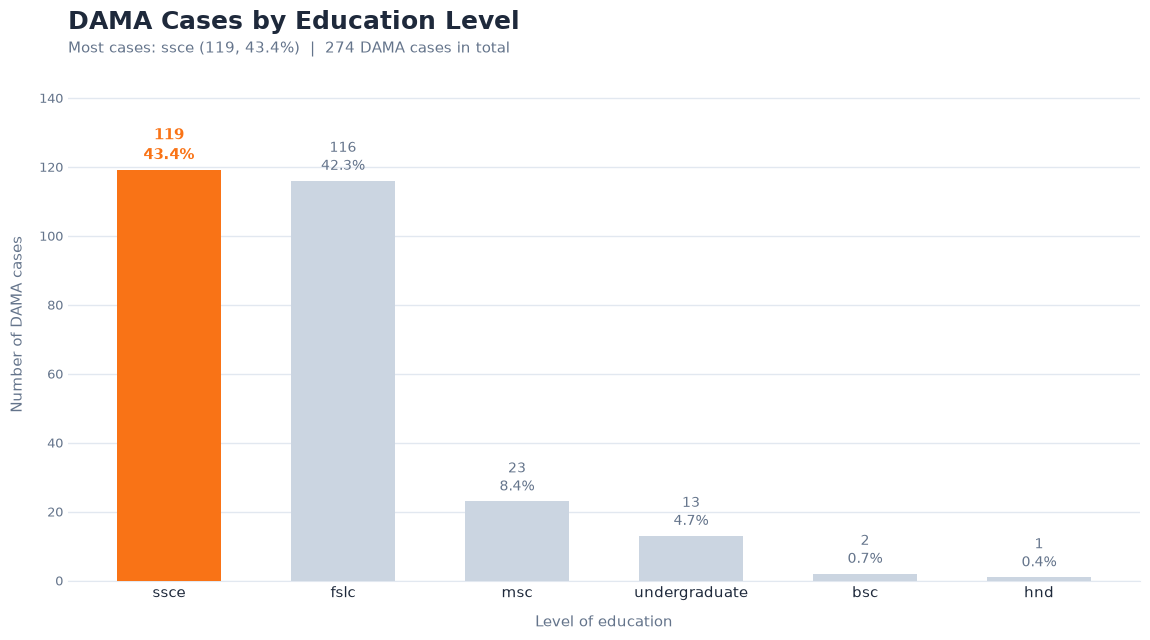

In [155]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# Optional: set your own order (lowest to highest education) to show levels in that order
# instead of ranked by count, e.g. ["No formal", "Primary", "Secondary", "Tertiary"]
ORDER = None

# ---------------- Prep ----------------
data = lvl_of_education.copy()
data["pt_level_of_education"] = data["pt_level_of_education"].astype(str)

if ORDER:
    data["pt_level_of_education"] = data["pt_level_of_education"].str.strip()
    data = (data.set_index("pt_level_of_education")
            .reindex([o for o in ORDER if o in set(data["pt_level_of_education"])])
            .reset_index())
else:
    data = data.sort_values("count", ascending=False).reset_index(drop=True)

labels = data["pt_level_of_education"].apply(lambda s: textwrap.fill(s, 14))
counts = data["count"]
pcts   = data["pct"]
total  = int(lvl_of_education["count"].sum())

hi = int(counts.values.argmax())

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, len(data) * 1.6 + 2), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(labels, counts, color=colors, width=0.6, zorder=3)

# Labels: count on top, share of all DAMA cases underneath
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}\n{p:.1f}%" for c, p in zip(counts, pcts)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Titles
ax.set_title("DAMA Cases by Education Level", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most cases: {data['pt_level_of_education'].iloc[hi]} "
        f"({counts.iloc[hi]:,.0f}, {pcts.iloc[hi]:.1f}%)  |  {total:,} DAMA cases in total",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Level of education", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Number of DAMA cases", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, counts.max() * 1.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/dama_by_education.png", dpi=180)
plt.show()

In [156]:
no_improvement = df.iloc[df["reason_for_dama"] == "no improvement"]
print(f"doctor that are involved in no improvement dama cases")
no_improvement["doctor"].value_counts()
no_improvement_cases = df[df["reason_for_dama"] == "no improvement"].groupby("doctor").agg(
    count = ("pt_id","count")
).reset_index().sort_values(by="count",ascending=False)
no_improvement_cases["pct"] = ( no_improvement_cases["count"]/no_improvement_cases["count"].sum() * 100).round(2)
no_improvement_cases

doctor that are involved in no improvement dama cases


,doctor,count,pct
3,dr badmus,6,31.58
5,dr ekwe,4,21.05
2,dr ayeni,4,21.05
1,dr anyanwu,2,10.53
0,dr abah,1,5.26
4,dr dase,1,5.26
6,dr oikeh,1,5.26


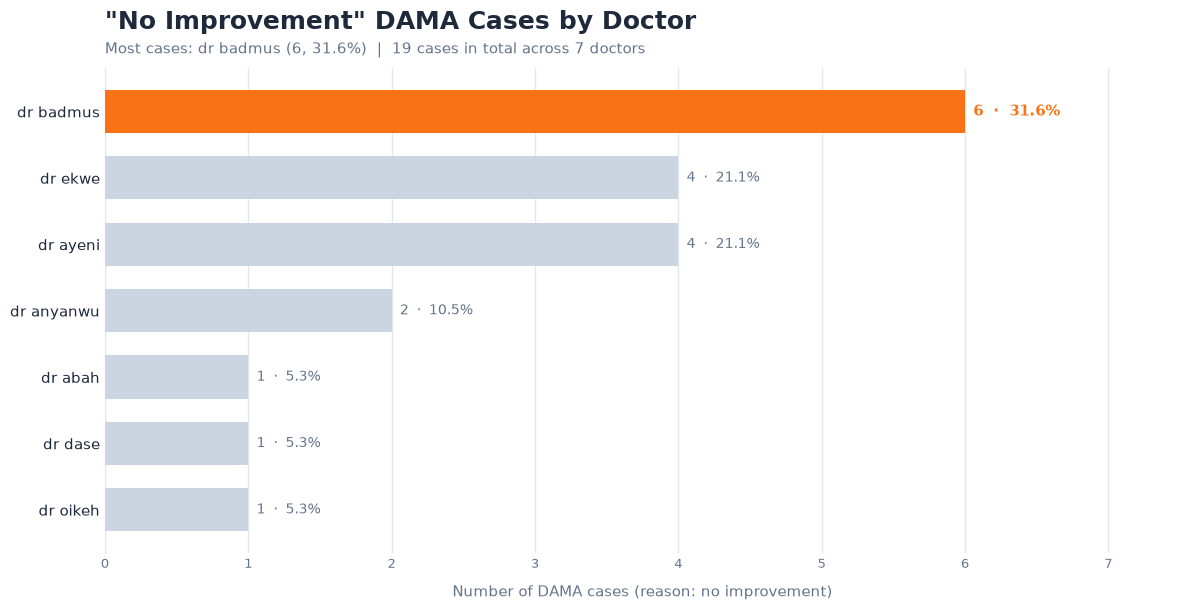

In [157]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 15   # max doctors to show

# ---------------- Prep ----------------
data = (no_improvement_cases.sort_values("count", ascending=False)
        .head(TOP_N).reset_index(drop=True))
labels = data["doctor"].astype(str).apply(lambda s: textwrap.fill(s, 28))
counts = data["count"]

total_all = no_improvement_cases["count"].sum()
shares    = counts / total_all * 100
top_doc   = data["doctor"].iloc[0]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12, max(4.5, len(data) * 0.6 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
bars = ax.barh(labels, counts, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()   # highest at the top

# Labels: count and share of all "no improvement" cases
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}  ·  {s:.1f}%" for c, s in zip(counts, shares)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Titles
ax.set_title('"No Improvement" DAMA Cases by Doctor', loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most cases: {top_doc} ({counts.iloc[0]:,.0f}, {shares.iloc[0]:.1f}%)  |  "
        f"{total_all:,.0f} cases in total across {len(no_improvement_cases)} doctors",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of DAMA cases (reason: no improvement)", fontsize=11,
              color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/no_improvement_by_doctor.png", dpi=180)
plt.show()

In [158]:
# dama cases by doctor specializatiion
specialization = df[df["dama"] == "yes"].groupby(["doctors_specialization"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values(by="count",ascending=False)
specialization["total_count"] = specialization["count"].sum()
specialization["pct"] = (specialization["count"]/specialization["total_count"] * 100).round(2)
specialization

,doctors_specialization,count,total_count,pct
3,emergency medicine,82,276,29.71
4,general surgery,54,276,19.57
5,nephrology,45,276,16.30
1,cardiology,40,276,14.49
0,anesthesiology,29,276,10.51
2,dermatology,15,276,5.43
6,orthopedics,11,276,3.99


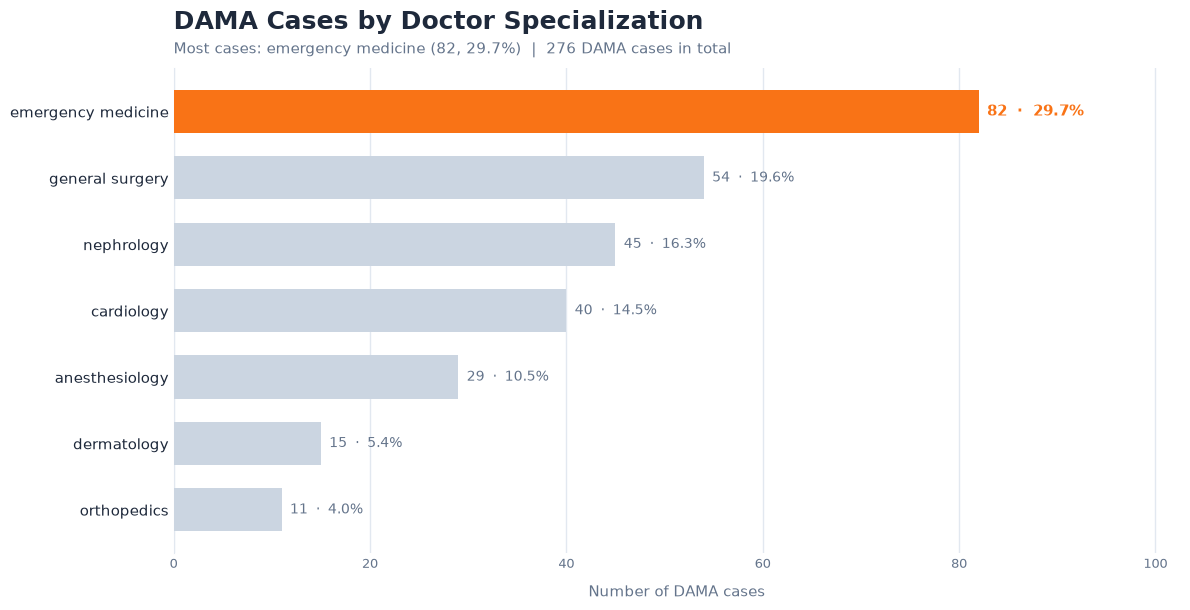

In [164]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 12   # max specializations to show

# ---------------- Prep ----------------
data = (specialization.sort_values("count", ascending=False)
        .head(TOP_N).reset_index(drop=True))
labels = data["doctors_specialization"].astype(str).apply(lambda s: textwrap.fill(s, 30))
counts = data["count"]

total_all = int(specialization["count"].sum())
shares    = counts / total_all * 100
top_spec  = data["doctors_specialization"].iloc[0]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12, max(4.5, len(data) * 0.6 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
bars = ax.barh(labels, counts, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()   # most cases at the top

# Labels: count and share of all DAMA cases
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}  ·  {s:.1f}%" for c, s in zip(counts, shares)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Titles
ax.set_title("DAMA Cases by Doctor Specialization", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most cases: {top_spec} ({counts.iloc[0]:,.0f}, {shares.iloc[0]:.1f}%)  |  "
        f"{total_all:,} DAMA cases in total",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of DAMA cases", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/dama_by_specialization.png", dpi=180)
plt.show()

In [159]:
admission_duration = df[df["dama"] == "yes"].groupby(["admission_group"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values(by="count",ascending=False)
admission_duration["total_count"] = admission_duration["count"].sum()
admission_duration["pct"] = (admission_duration["count"]/admission_duration["total_count"] * 100).round(2)
admission_duration

,admission_group,count,total_count,pct
0,Extended stay,85,276,30.80
2,Moderate stay,72,276,26.09
1,Long stay,55,276,19.93
3,Short stay,52,276,18.84
4,Very long stay,12,276,4.35


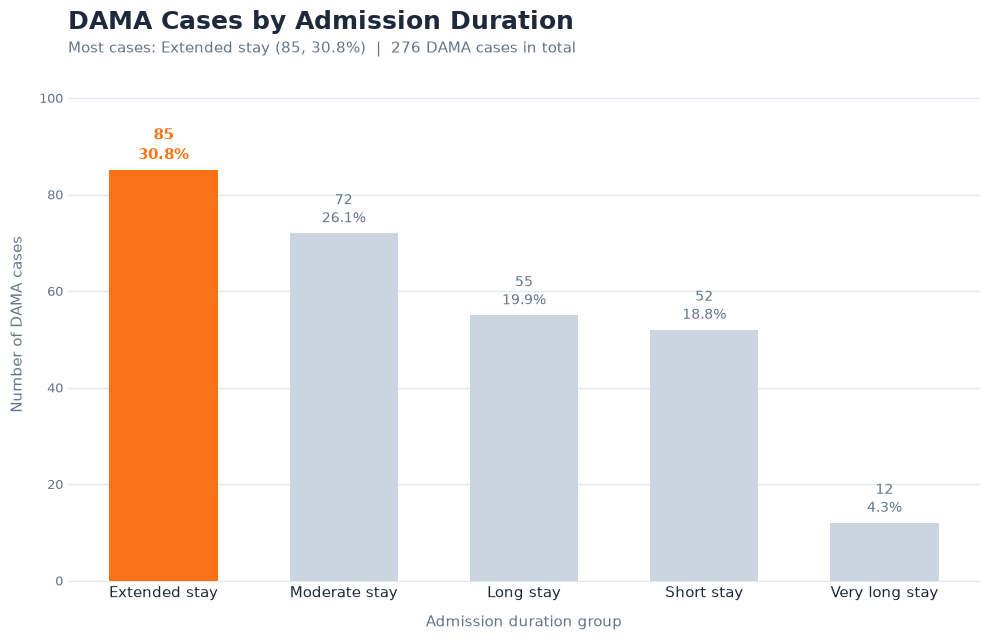

In [160]:


# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
data = admission_duration.copy()
data["admission_group"] = data["admission_group"].astype(str)

# Natural order (shortest to longest) using the first number in each label, e.g. "1-3 days", "4-7 days"
nums = data["admission_group"].str.extract(r"(\d+)")[0]
if nums.notna().all():
    data = data.assign(_k=nums.astype(int)).sort_values("_k").drop(columns="_k")
else:
    data = data.sort_values("count", ascending=False)   # no numbers in labels: rank by count
data = data.reset_index(drop=True)

labels = data["admission_group"].apply(lambda s: textwrap.fill(s, 14))
counts = data["count"]
pcts   = data["pct"]
total  = int(admission_duration["count"].sum())

hi = int(counts.values.argmax())

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(10, len(data) * 1.6 + 2), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(labels, counts, color=colors, width=0.6, zorder=3)

# Labels: count on top, share of all DAMA cases underneath
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}\n{p:.1f}%" for c, p in zip(counts, pcts)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Titles
ax.set_title("DAMA Cases by Admission Duration", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most cases: {data['admission_group'].iloc[hi]} "
        f"({counts.iloc[hi]:,.0f}, {pcts.iloc[hi]:.1f}%)  |  {total:,} DAMA cases in total",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Admission duration group", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Number of DAMA cases", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, counts.max() * 1.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/dama_by_admission_duration.png", dpi=180)
plt.show()

In [161]:
occupation = df[df["dama"] == "yes"].groupby(["pt_occupation"]).agg(
    count = ("pt_id","count")
).reset_index().sort_values("count",ascending=False)
occupation["total_count"] = occupation["count"].sum()
occupation["pct"] = (occupation["count"]/occupation["total_count"] * 100).round(2)
occupation.head() 

,pt_occupation,count,total_count,pct
36,trading,87,276,31.52
15,farming,30,276,10.87
28,retiree,23,276,8.33
32,student,22,276,7.97
13,dependant,17,276,6.16


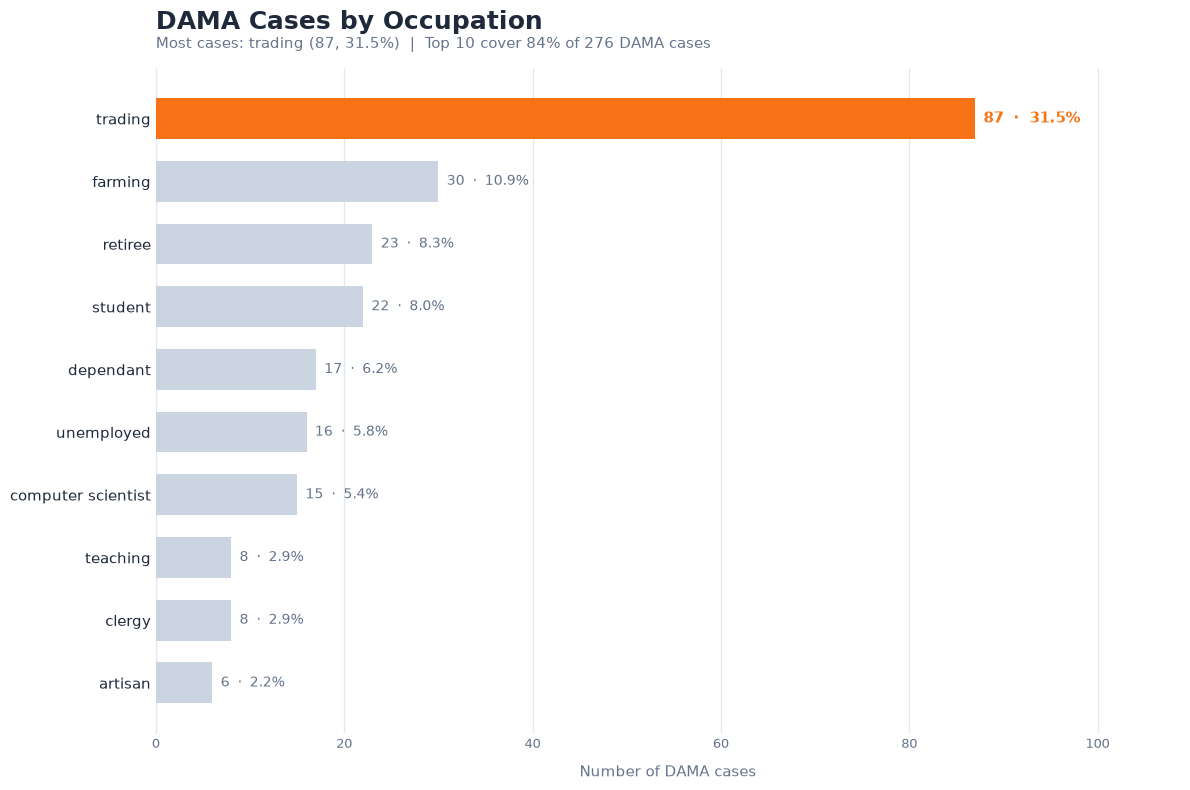

In [162]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 10   # max occupations to show

# ---------------- Prep ----------------
data = (occupation.sort_values("count", ascending=False)
        .head(TOP_N).reset_index(drop=True))
labels = data["pt_occupation"].astype(str).apply(lambda s: textwrap.fill(s, 28))
counts = data["count"]

total_all = int(occupation["count"].sum())
shares    = counts / total_all * 100
top_occ   = data["pt_occupation"].iloc[0]
shown_pct = shares.sum()

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12, max(4.5, len(data) * 0.6 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
bars = ax.barh(labels, counts, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()   # most cases at the top

# Labels: count and share of all DAMA cases
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}  ·  {s:.1f}%" for c, s in zip(counts, shares)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Titles
ax.set_title("DAMA Cases by Occupation", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most cases: {top_occ} ({counts.iloc[0]:,.0f}, {shares.iloc[0]:.1f}%)  |  "
        f"Top {len(data)} cover {shown_pct:.0f}% of {total_all:,} DAMA cases",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of DAMA cases", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/dama_by_occupation.png", dpi=180)
plt.show()

In [163]:
for disease in diseases:
    print(disease)
    disease = df[(df[disease] == "yes") & (df["dama"] == "yes")].groupby("admission_group").agg(
        count = ("pt_id","count")
    ).reset_index()
    print(disease)
    print()

dama
  admission_group  count
0   Extended stay     85
1       Long stay     55
2   Moderate stay     72
3      Short stay     52
4  Very long stay     12

ckd
  admission_group  count
0   Extended stay     16
1       Long stay     10
2   Moderate stay     12
3      Short stay     11
4  Very long stay      5

pud
  admission_group  count
0   Extended stay      7
1       Long stay      4
2   Moderate stay      2
3      Short stay      9
4  Very long stay      2

stroke
  admission_group  count
0   Extended stay     21
1       Long stay     11
2   Moderate stay     11
3      Short stay     14
4  Very long stay      4

dm
  admission_group  count
0   Extended stay      6
1       Long stay      6
2   Moderate stay      6
3      Short stay      4
4  Very long stay      3

cancer
  admission_group  count
0   Extended stay      1
1       Long stay      1
2   Moderate stay      1
3      Short stay      1

